# CSCI1409 Deep Learning — Week 4 SIS Mini-project 1
## FashionMNIST: train your first MLP and read its loss curves

**SIS mini-project 1:** 4 course points · **Defense:** in class, Week 4  
**Goal:** build a small neural network (MLP), train it twice — once with **SGD** and once with **Adam** — and plot how the **loss** changes on training and validation data.

You work in groups of 3. Apart from the dataset download, **all code in this notebook is written by your group.** The cells only contain `# TODO` comments with hints. Every student must be able to explain every line and every plot. Write short answers in the answer cells (2–3 sentences each is enough).

**Before class:** make sure `torch`, `torchvision`, and `matplotlib` are installed ([PyTorch setup guide](https://pytorch.org/get-started/locally/)). The first download of FashionMNIST needs internet. **A CPU is enough** — no GPU needed.

### AI-use rule for this lab (Level C — AI-Assisted)

You may use generative AI to get ideas, explain concepts, debug code, or get feedback. However, **your group must write the main solution yourselves** and **understand and check everything you submit**. At the defense you will explain your code and plots without AI help — "the AI wrote it" is not an answer.

Check AI explanations against the lectures and the PyTorch documentation. Plagiarism, copying another group's code, and invented results are not allowed under any circumstances. If you used an external source (tutorial, blog, docs), name it in your answers.

## 1. Dataset

FashionMNIST has 28×28 grayscale images of clothing in 10 classes (T-shirt, trouser, sneaker, …). The download code is given. We use only the **official training portion**; the official test set is not used today.

Key words:
- **Training set** — the images the model learns from (used to compute gradients).
- **Validation set** — images the model never learns from; we use them only to check how well it works on *new* data.

In [79]:
# PROVIDED: download/load the official training portion.
# ToTensor gives each image the shape [1, 28, 28] with pixel values in [0, 1].
from torchvision import datasets, transforms

DATA_ROOT = "./data"

full_training_data = datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)
print("Official training portion:", len(full_training_data), "images")
print("Classes:", full_training_data.classes)

Official training portion: 60000 images
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [80]:
# TODO: import what you need (torch, torch.nn, DataLoader, random_split, matplotlib, ...)
# TODO: fix a random seed (e.g. torch.manual_seed(42)) so your results are repeatable

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)

In [81]:
# TODO: take a random subset of 6,000 images and split it into 5,000 train and 1,000 val
#       hint: torch.utils.data.random_split with a torch.Generator seeded by your seed
# TODO: print the number of train and val images

g = torch.Generator().manual_seed(SEED)
train_set, val_set, _ = random_split(full_training_data, [5000, 1000, 54000], generator=g)
print(len(train_set), len(val_set))

5000 1000


torch.Size([1, 28, 28]) 9


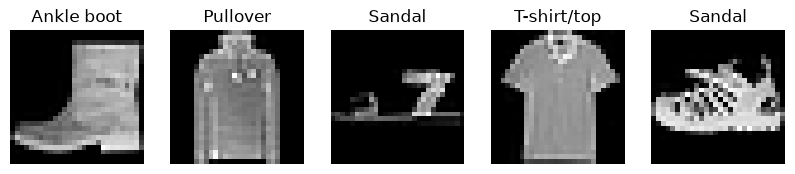

In [82]:
# TODO: print the shape and label of one training image
# TODO: show 5 training images with their class names (matplotlib)

img, label = train_set[0]
print(img.shape, label)

fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for ax, i in zip(axes, range(5)):
    img, label = train_set[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(full_training_data.classes[label])
    ax.axis("off")
plt.show()

**Your answer — dataset**

- How many images are in train and in val?
- What does the shape `[1, 28, 28]` mean?
- Why must validation images never be used to update the model's weights?

**Answers**

- 6000 images in train and 1,000 images in val
- 1 channel (grayscale), 28 pixels high, 28 pixels wide. Each value is a pixel brightness in [0, 1].
- If the model learned from it, the val loss would no longer show how well the model generalizes, and we could not detect overfitting.

## 2. Build your model

Design a small **MLP** (multi-layer perceptron). Requirements:

- input: a batch of images of shape `[1, 28, 28]` → flatten to 784 numbers
- at least **one hidden layer** with a nonlinearity (e.g. ReLU)
- output: **10 numbers per image** (one score — a *logit* — per class)

A simple design is enough, e.g. `784 → 128 → 10`.

In [83]:
# TODO: define your MLP as an nn.Module (or nn.Sequential)
#       hint: nn.Flatten, nn.Linear, nn.ReLU

def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )

model = make_model()
x, y = next(iter(DataLoader(train_set, batch_size=8)))
print(model(x).shape)

torch.Size([8, 10])


In [84]:
# TODO: pass a small batch of images through the model and check the output shape is (batch_size, 10)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=64, shuffle=False)
loss_fn = nn.CrossEntropyLoss()

**Your answer — model**

- Write your architecture (layer sizes and activation).
- Why do we need a nonlinearity between the layers?


**Answers**


- Input is vector with 784 pixels passes through one hidden layer of 128 neurons with ReLU, and the output layer gives 10 logits. 
- Without it, two stacked linear layers collapse into a single linear layer, so the model could only learn linear decision boundaries. ReLU lets the network learn more complex, nonlinear patterns

## 3. Training setup

Use these **suggested settings** (you may change them, but write down what you used):

| Setting | Suggested value |
|---|---|
| Batch size | 64 |
| Epochs | 10 |
| SGD learning rate | 0.1 |
| Adam learning rate | 0.001 |

Keep the model, seed, batch size, and number of epochs **the same** for SGD and Adam — only the optimizer changes. That way the comparison is fair.

In [85]:
# TODO: create a DataLoader for train (shuffle=True) and one for val (shuffle=False)
# TODO: choose a loss function for 10-class classification

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    for x, y in loader:
        optimizer.zero_grad()
        out = model(x) 
        loss = loss_fn(out, y)
        loss.backward() 
        optimizer.step() 

def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def run_experiment(optimizer_name, lr, epochs=10):
    torch.manual_seed(SEED)
    model = make_model()
    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses, val_accs = [], [], []
    for epoch in range(1, epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        tr_loss, _ = evaluate(model, train_loader, loss_fn)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        train_losses.append(tr_loss)
        val_losses.append(va_loss)
        val_accs.append(va_acc)
        print(f"Epoch {epoch}: train {tr_loss:.4f} | val {va_loss:.4f} | val acc {va_acc:.3f}")
    return train_losses, val_losses, val_accs

**Your prediction (write it BEFORE training)**

- Which optimizer do you think will make the training loss go down faster: SGD or Adam? Why?


**Answers**

- I think Adam will reduce the training loss faster. Adam adapts the step size for each weight separately and uses momentum, so it usually makes progress quickly even with a small learning rate. SGD uses the same step for all weights, so it can be slower.

## 4. Training and evaluation code

Write two functions yourselves:

1. **`train_one_epoch`** — goes through all training batches once. For each batch:  
   (a) clear old gradients → (b) forward pass → (c) compute the loss → (d) backpropagate → (e) update the weights.  
   Use `model.train()`.
2. **`evaluate`** — returns the average loss and accuracy on a loader. Use `model.eval()` and `torch.no_grad()`, so **no gradients and no weight updates** happen here.

At the defense you must point to the lines (a)–(e) in your code.

In [86]:
# TODO: write train_one_epoch(model, loader, loss_fn, optimizer)
#       zero_grad -> forward -> loss -> backward -> step

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    for x, y in loader:
        optimizer.zero_grad()      # (a) очистить старые градиенты
        out = model(x)             # (b) прямой проход
        loss = loss_fn(out, y)     # (c) посчитать loss
        loss.backward()            # (d) обратное распространение
        optimizer.step()           # (e) обновить веса

In [87]:
# TODO: write evaluate(model, loader, loss_fn) that returns (average loss, accuracy)

def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

In [88]:
# TODO: write run_experiment(optimizer_name, lr) that:
#       - resets the seed and builds a NEW model (so both runs start from the same weights)
#       - creates the optimizer: torch.optim.SGD or torch.optim.Adam
#       - for each epoch: train once, then evaluate on train and on val
#       - stores train loss and val loss for every epoch in two lists and returns them
#       - prints epoch number, train loss, val loss, val accuracy




def run_experiment(optimizer_name, lr, epochs=10):
    torch.manual_seed(SEED)
    model = make_model()
    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses, val_accs = [], [], []
    for epoch in range(1, epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        tr_loss, _ = evaluate(model, train_loader, loss_fn)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        train_losses.append(tr_loss)
        val_losses.append(va_loss)
        val_accs.append(va_acc)
        print(f"Epoch {epoch}: train {tr_loss:.4f} | val {va_loss:.4f} | val acc {va_acc:.3f}")
    return train_losses, val_losses, val_accs

## 5. Run SGD and Adam

In [99]:
# TODO: run the experiment with SGD
sgd_train_losses, sgd_val_losses, sgd_val_accs = run_experiment(
    "SGD",
    lr=0.0000001,
    epochs=10
)

Epoch 1: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 2: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 3: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 4: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 5: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 6: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 7: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 8: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 9: train 2.3054 | val 2.3061 | val acc 0.117
Epoch 10: train 2.3054 | val 2.3061 | val acc 0.117


In [90]:
# TODO: run the experiment with Adam
adam_train_losses, adam_val_losses, adam_val_accs = run_experiment(
    "Adam",
    lr=0.001,
    epochs=10
)

Epoch 1: train 0.7178 | val 0.7120 | val acc 0.742
Epoch 2: train 0.5861 | val 0.6038 | val acc 0.787
Epoch 3: train 0.5295 | val 0.5706 | val acc 0.809
Epoch 4: train 0.4846 | val 0.5390 | val acc 0.810
Epoch 5: train 0.4689 | val 0.5377 | val acc 0.808
Epoch 6: train 0.4409 | val 0.5226 | val acc 0.813
Epoch 7: train 0.4140 | val 0.5034 | val acc 0.829
Epoch 8: train 0.4550 | val 0.5553 | val acc 0.798
Epoch 9: train 0.3909 | val 0.4995 | val acc 0.817
Epoch 10: train 0.3688 | val 0.4896 | val acc 0.824


## 6. Plot the loss curves

This is the main result of the lab. A **loss curve** shows the loss (y-axis) after each epoch (x-axis).

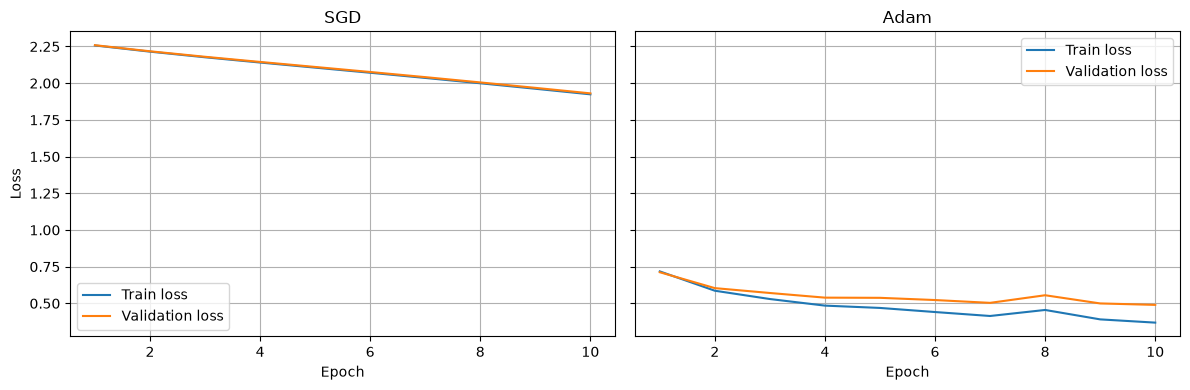

SGD final results:
Train loss: 1.9240
Validation loss: 1.9307
Validation accuracy: 0.532

Adam final results:
Train loss: 0.3688
Validation loss: 0.4896
Validation accuracy: 0.824


In [91]:
# TODO: plot train loss and val loss vs epoch for SGD and for Adam
#       (e.g. two panels side by side, same y-axis range; add a title, axis labels, and a legend)
# TODO: print the final train loss, final val loss, and final val accuracy for both runs
epochs = range(1, 11)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
    sharey=True
)

# SGD
axes[0].plot(
    epochs,
    sgd_train_losses,
    label="Train loss"
)

axes[0].plot(
    epochs,
    sgd_val_losses,
    label="Validation loss"
)

axes[0].set_title("SGD")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


# Adam
axes[1].plot(
    epochs,
    adam_train_losses,
    label="Train loss"
)

axes[1].plot(
    epochs,
    adam_val_losses,
    label="Validation loss"
)

axes[1].set_title("Adam")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


print("SGD final results:")
print(f"Train loss: {sgd_train_losses[-1]:.4f}")
print(f"Validation loss: {sgd_val_losses[-1]:.4f}")
print(f"Validation accuracy: {sgd_val_accs[-1]:.3f}")


print("\nAdam final results:")
print(f"Train loss: {adam_train_losses[-1]:.4f}")
print(f"Validation loss: {adam_val_losses[-1]:.4f}")
print(f"Validation accuracy: {adam_val_accs[-1]:.3f}")

**Your answer — curves**

- Which optimizer reduced the training loss faster? Give one epoch and the numbers.
- Was your prediction correct?
- Look at the gap between train loss and val loss. Is the model overfitting (val loss goes up while train loss keeps going down), underfitting (both stay high), or fitting well?
- The two optimizers used different learning rates. Why does that make the comparison less clear-cut?

**Answers**

- Adam. At epoch 1 its train loss was ≈0.72 vs ≈1.25 for SGD. At epoch 10 it was 0.3688 vs 1.1951 for SGD.
- Yes. We predicted Adam would be faster because it adapts the step for each weight and uses momentum. Adam also gave a much better validation accuracy (0.824 vs 0.645).
- Adam is fitting well, with only a slight start of overfitting: val loss (0.4896) stays above train loss (0.3688) and flattens after epoch 7, while train loss keeps going down. SGD is not overfitting, because train and val losses are close, but both are high and jump up and down. The training is unstable, not smoothly underfitting.
- SGD with lr=0.1 is probably too large, which causes the oscillations and the spike at epoch 10. So SGD may be bad here because of its learning rate, not because of the algorithm. With a smaller lr (e.g. 0.01) SGD would likely behave much better.

## 7. Group contribution statement (required)

For each member, write what they did (e.g. data split, model, training loop, plots, answers) and how the group used AI (what for, and how you checked it). Every member must still be able to explain the whole notebook.

| Student (full name) | Main contribution | How AI was used and checked |
|---|---|---|
| Bakhramov Abdulaziz | Data loading and Training  | Used AI to explain concepts |
| Karsybayev Abylaikhan | running SGD and Adam experiments, plotting the loss curves | Used AI to explain the training steps |

## 8. Defense checklist and grading

**Submit this completed notebook** (or an HTML/PDF export with all cells and plots visible) before your defense. Each group has a short (~5 min) defense. Any member may be asked to:

- explain any line of your code — the split, the model, and the training steps (a)–(e)
- explain why `model.eval()` and `torch.no_grad()` are used in `evaluate`
- read your loss plots: which optimizer was faster, and is there overfitting?
- say what AI helped with and how you checked it

The Week 4 SIS mini-project is worth **4 points**:

| Criterion | Points |
|---|---|
| Working code written by the group: data split, MLP, training loop, and evaluation; both SGD and Adam runs complete | 1 |
| Clear loss plots: train and val loss vs epoch for both optimizers, with title, axis labels, and legend | 1 |
| Answers: correct, short explanations of the dataset, model, and curves, based on your own numbers | 1 |
| Individual oral explanation of the group's code and plots at the defense | 1 |
| **Total** | **4** |

**Optional (no extra points):** add dropout (`nn.Dropout(0.3)`) after the hidden layer, train with Adam again, and compare the new loss curves with your old Adam curves. Did the train/val gap change?